<a href="https://colab.research.google.com/github/Tonioord/TGVH-DS/blob/main/TGVH.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
import pandas as pd

In [5]:
url_github= "https://github.com/Tonioord/TGVH-DS/raw/refs/heads/main/ExportacionGit.csv"
df = pd.read_csv(url_github, encoding='latin-1')

In [6]:
print(f"Dimensiones del dataset: {df.shape}")
display(df.head())

Dimensiones del dataset: (4462, 17)


,AGENDA,TIPO VISITA,FECHA,INICIO,MASCOTA,RESPONSABLE VISITA,ESPECIE,RAZA,ASUNTO,MASCOTA_SEXO,PROPIETARIO,FECHA CREACION CITA,USUARIO CREACIÓN CITA,USUARIO MODIFICACIÓN CITA,PROCEDENCIA,COMUNICACION_IDCLIENTE,COMUNICACION_IDANIMAL
0,MEDICINA FELINA,CONSULTA GENERAL SEGUIMIENTO,27/02/2026,11:00,TERPENA ESCOBAR,Carmen Lizzeth Espinosa Fuentez,FELINA,Europeo de pelo corto,Consulta por llamada,Hembra,ROSA MARIA ESCOBAR,26/03/2026 18:45,Montserrat Hernández Betancourt,Montserrat Hernández Betancourt,NaN,831252,831253
1,MEDICINA INTERNA CANINOS,CONSULTA GENERAL SEGUIMIENTO,02/03/2026,10:00,DUMPLING ORTIZ,Brenda Nicole Suárez González,CANINA,Mestizo,SEGUIMIENTO,Hembra,ALEJANDRA ORTIZ ACEVES,02/03/2026 10:00,Brenda Nicole Suárez González,NaN,NaN,830385,830386
2,MEDICINA INTERNA CANINOS,CONSULTA GENERAL,02/03/2026,10:29,MOLLY,Brenda Nicole Suárez González,CANINA,Pomerania,2DA OPINION,Hembra,ENRIQUE CORDOVA TELLEZ,02/03/2026 10:30,Brenda Nicole Suárez González,NaN,NaN,830390,830391
3,MEDICINA INTERNA CANINOS,CONSULTA GENERAL,02/03/2026,13:00,KAI SAAVEDRA,Livier Delgadillo Quezada,CANINA,Golden Retriever,CONSULTA GENERAL,Macho,ANA SAAVEDRA GALLARDO,02/03/2026 12:54,Monica Abigail Hernandez Nava,NaN,NaN,830404,830406
4,MEDICINA INTERNA CANINOS,CONSULTA GENERAL,02/03/2026,14:00,DUKE ARROYO,Hugo Enrique Romero Ambris,CANINA,Husky Siberiano,CONSULTA GENERAL,Macho,ARTURO ARROYO CASTELLANOS,02/03/2026 13:52,Monica Abigail Hernandez Nava,NaN,NaN,830407,830408


In [10]:
# 2. Limpiar nombres de columnas (quitar espacios en blanco al inicio o final)
df.columns = df.columns.str.strip()

# 3. Conversión de Fechas (Cuidado con los formatos)
# Convertimos a formato fecha para poder extraer meses, días y calcular tiempos
df['FECHA_DT'] = pd.to_datetime(df['FECHA'], format='%d/%m/%Y', errors='coerce')
df['FECHA_CREACION_DT'] = pd.to_datetime(df['FECHA CREACION CITA'], errors='coerce')
df['HORA_INICIO'] = pd.to_datetime(df['INICIO'], format='%H:%M', errors='coerce').dt.hour

# 4. Estandarización de Texto
# Columnas que necesitamos unificar para evitar conteos duplicados
columnas_texto = ['AGENDA', 'TIPO VISITA', 'ESPECIE', 'RAZA', 'ASUNTO', 'MASCOTA_SEXO']
for col in columnas_texto:
    # Convertir a string, quitar espacios en los bordes y pasar a mayúsculas
    df[col] = df[col].astype(str).str.strip().str.upper()

# 5. Normalización agresiva de la columna 'ASUNTO'
# Mapeamos las variaciones de recepción a categorías limpias
mapeo_asuntos = {
    'CONSULTA DE 1RA VEZ': 'PRIMERA VEZ',
    'CONSULTA DE PRIMERA VEZ': 'PRIMERA VEZ',
    'CONSULTA DE SEGUIMIENTO': 'SEGUIMIENTO',
    'REVISION': 'SEGUIMIENTO'
}
df['ASUNTO_LIMPIO'] = df['ASUNTO'].replace(mapeo_asuntos)

# Identificar con una bandera si la consulta contiene la palabra seguimiento o primera vez
df.loc[df['ASUNTO'].str.contains('SEGUIMIENTO', na=False), 'ASUNTO_LIMPIO'] = 'SEGUIMIENTO'
df.loc[df['ASUNTO'].str.contains('1RA VEZ|PRIMERA VEZ', na=False), 'ASUNTO_LIMPIO'] = 'PRIMERA VEZ'

# 6. Eliminar registros basura
df = df.dropna(subset=['FECHA_DT']) # Quitar filas sin fecha válida
df = df.drop_duplicates()           # Quitar filas idénticas duplicadas por error del sistema

# Mostrar el resultado
print(f"Dimensiones de la base limpia: {df.shape}")
print("\nEjemplo de los primeros 3 registros limpios:")
display(df[['FECHA_DT', 'HORA_INICIO', 'ESPECIE', 'RAZA', 'ASUNTO_LIMPIO']].head(3))

/tmp/ipykernel_619/1891887063.py:7: UserWarning: Parsing dates in %d/%m/%Y %H:%M format when dayfirst=False (the default) was specified. Pass `dayfirst=True` or specify a format to silence this warning.
  df['FECHA_CREACION_DT'] = pd.to_datetime(df['FECHA CREACION CITA'], errors='coerce')


Dimensiones de la base limpia: (4462, 21)

Ejemplo de los primeros 3 registros limpios:


,FECHA_DT,HORA_INICIO,ESPECIE,RAZA,ASUNTO_LIMPIO
0,2026-02-27,11,FELINA,EUROPEO DE PELO CORTO,CONSULTA POR LLAMADA
1,2026-03-02,10,CANINA,MESTIZO,SEGUIMIENTO
2,2026-03-02,10,CANINA,POMERANIA,2DA OPINION


/tmp/ipykernel_619/71997556.py:16: UserWarning:

Parsing dates in %d/%m/%Y %H:%M format when dayfirst=False (the default) was specified. Pass `dayfirst=True` or specify a format to silence this warning.

/tmp/ipykernel_619/71997556.py:40: FutureWarning:



Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.


/tmp/ipykernel_619/71997556.py:59: FutureWarning:



Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.


/tmp/ipykernel_619/71997556.py:71: FutureWarning:



Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.


/tmp/ipykernel_619/71997556.py:81: FutureWarning:



Passing `palette` without assigning `hue` is deprecated and will be removed in v0.1

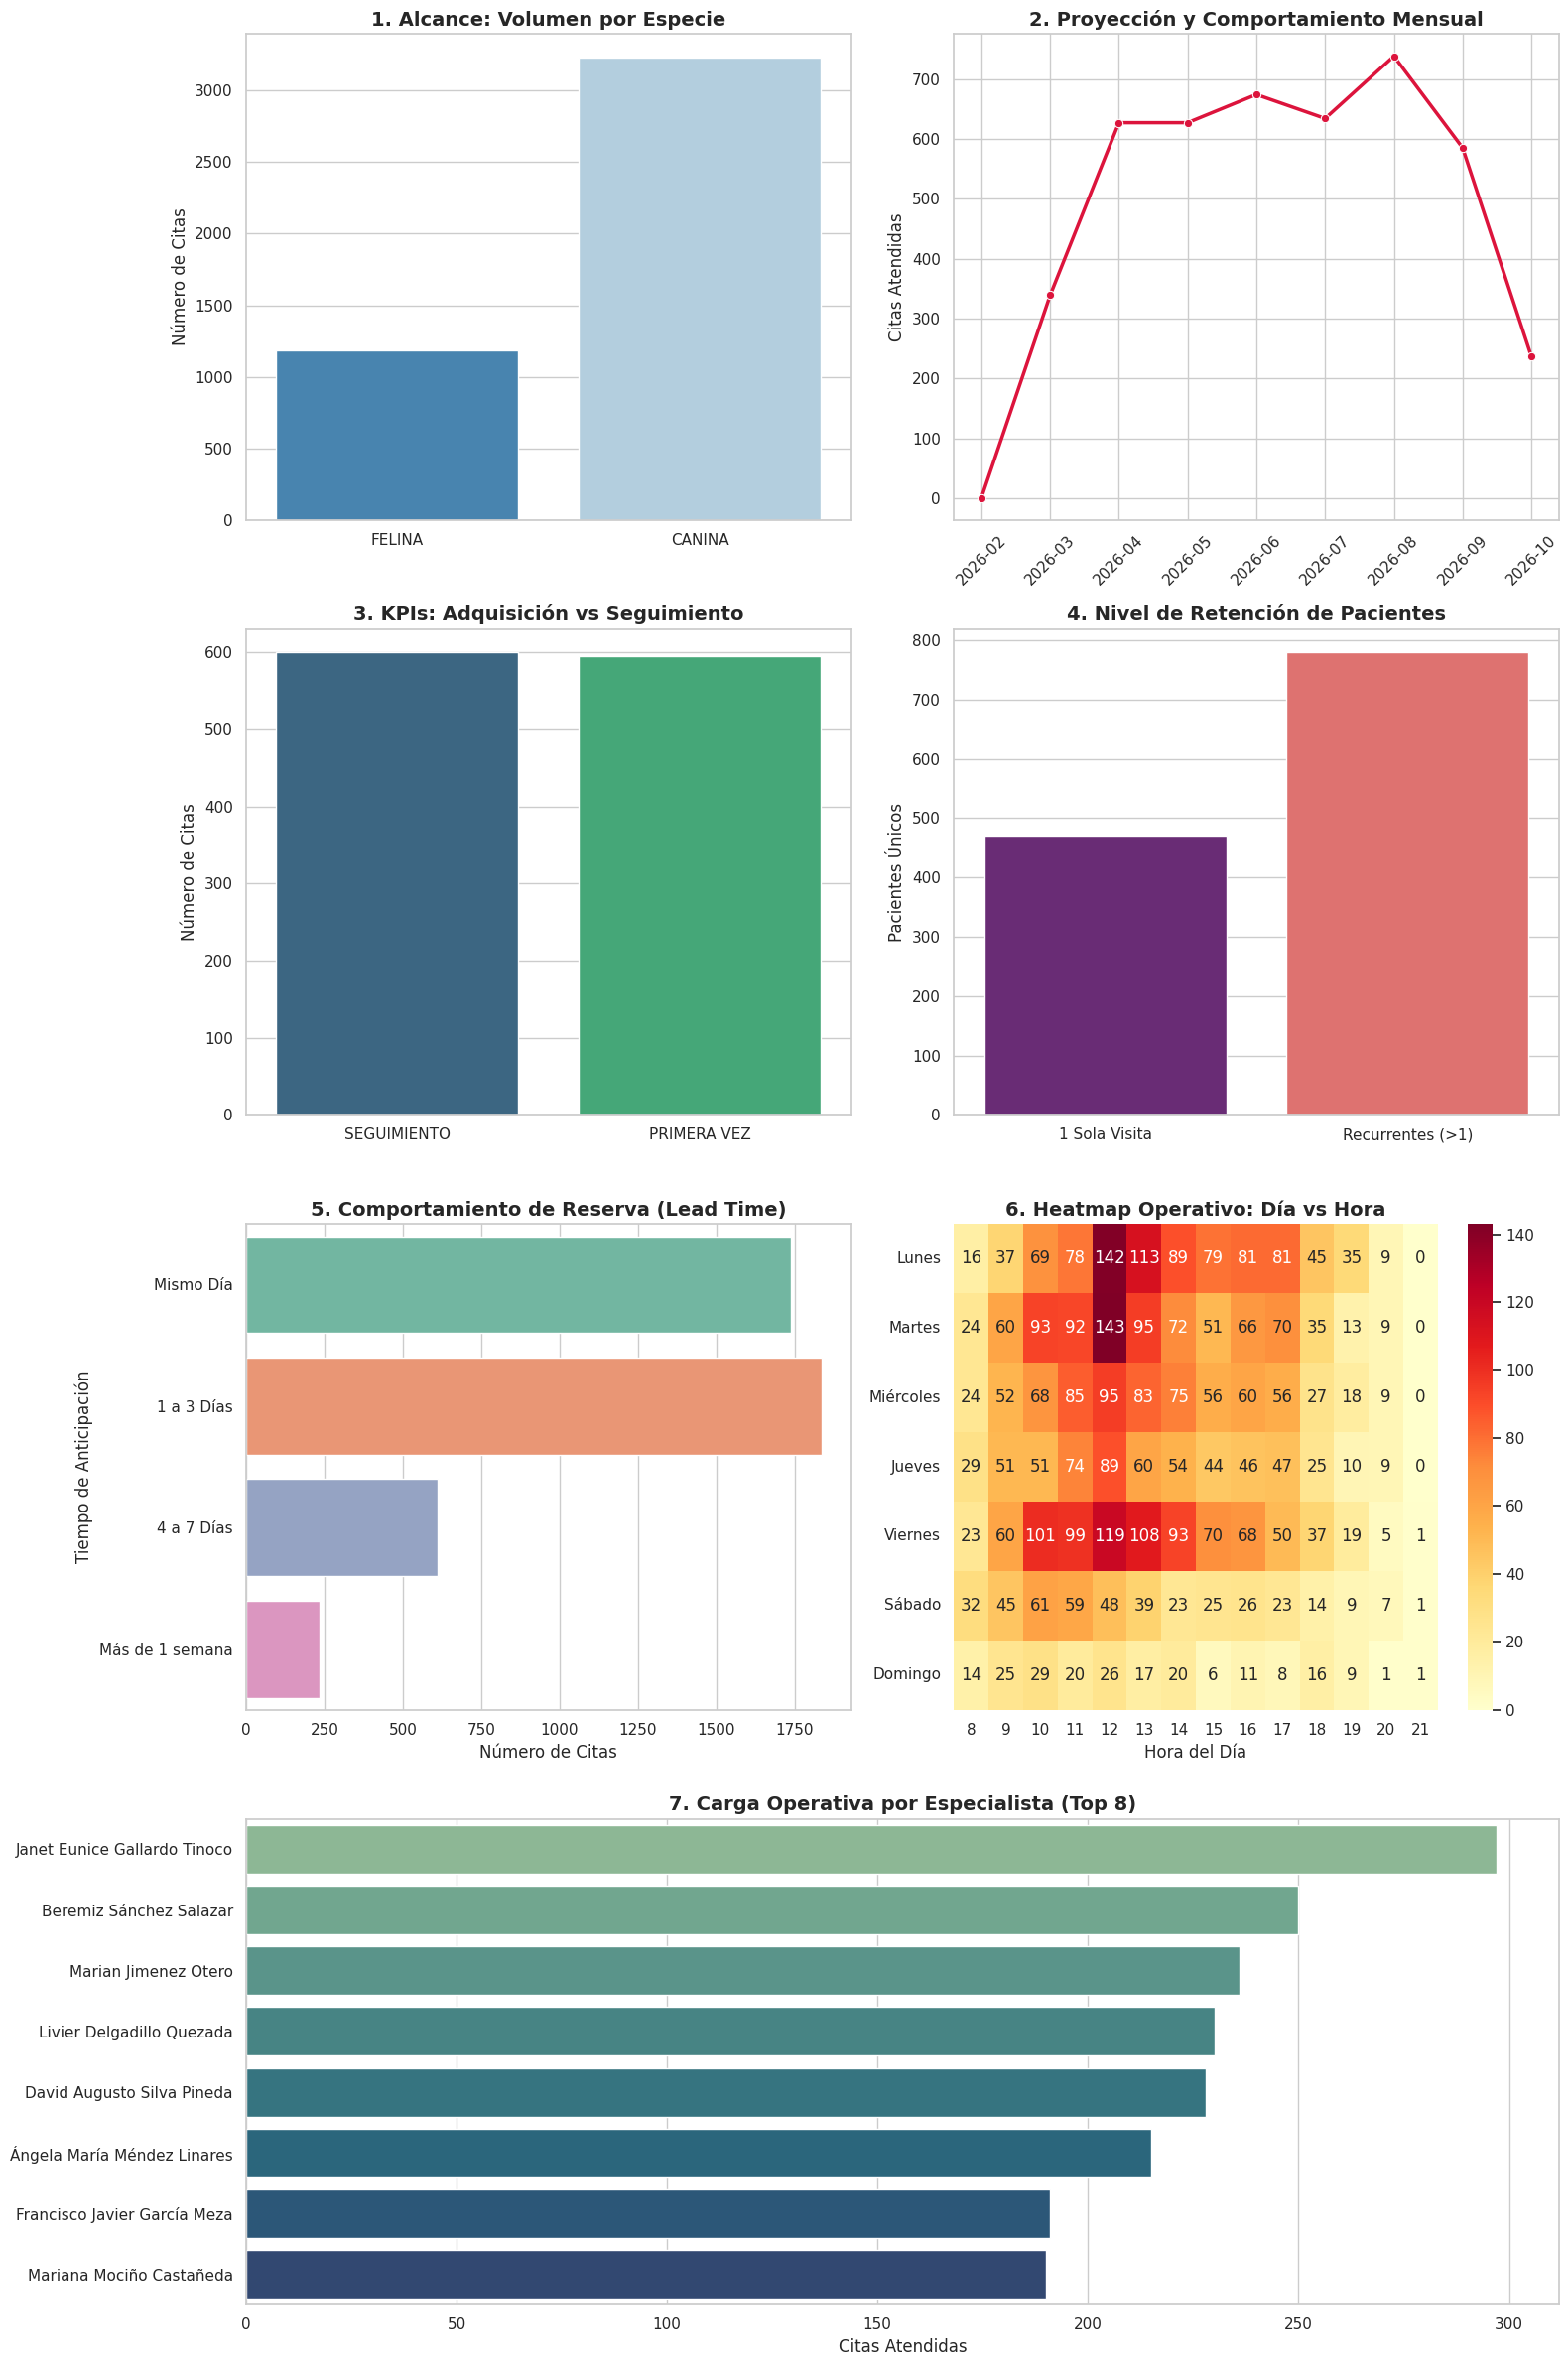

In [13]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Configuración visual de Seaborn
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (16, 24)

# 1. Cargar y limpiar datos
url = "https://github.com/Tonioord/TGVH-DS/raw/refs/heads/main/ExportacionGit.csv"
df = pd.read_csv(url, encoding='latin-1')
df.columns = df.columns.str.strip()

df['FECHA_DT'] = pd.to_datetime(df['FECHA'], format='%d/%m/%Y', errors='coerce')
df['FECHA_CREACION_DT'] = pd.to_datetime(df['FECHA CREACION CITA'], errors='coerce')
df['HORA_INICIO'] = pd.to_datetime(df['INICIO'], format='%H:%M', errors='coerce').dt.hour
df['DIA_SEMANA'] = df['FECHA_DT'].dt.day_name()

for col in ['AGENDA', 'TIPO VISITA', 'ESPECIE', 'RAZA', 'ASUNTO', 'MASCOTA_SEXO']:
    df[col] = df[col].astype(str).str.strip().str.upper()

df.loc[df['ASUNTO'].str.contains('SEGUIMIENTO', na=False), 'ASUNTO_LIMPIO'] = 'SEGUIMIENTO'
df.loc[df['ASUNTO'].str.contains('1RA VEZ|PRIMERA VEZ', na=False), 'ASUNTO_LIMPIO'] = 'PRIMERA VEZ'
df = df.dropna(subset=['FECHA_DT']).drop_duplicates()

# Cálculo de Lead Time (Anticipación)
df_valid = df.dropna(subset=['FECHA_CREACION_DT']).copy()
df_valid['LEAD_TIME'] = (df_valid['FECHA_DT'] - df_valid['FECHA_CREACION_DT'].dt.normalize()).dt.days
df_valid = df_valid[df_valid['LEAD_TIME'] >= 0]

# ==========================================
# CREACIÓN DEL DASHBOARD CON SEABORN
# ==========================================
fig = plt.figure()
fig.subplots_adjust(hspace=0.5, wspace=0.3)

# 1. Alcance
ax1 = plt.subplot(4, 2, 1)
sns.countplot(data=df[df['ESPECIE'].isin(['CANINA', 'FELINA'])], x='ESPECIE', palette='Blues_r', ax=ax1)
ax1.set_title('1. Alcance: Volumen por Especie', fontsize=14, fontweight='bold')
ax1.set_ylabel('Número de Citas')
ax1.set_xlabel('')

# 2. Comportamiento Mensual
ax2 = plt.subplot(4, 2, 2)
df_mensual = df['FECHA_DT'].dt.to_period('M').value_counts().sort_index().reset_index()
df_mensual.columns = ['Mes', 'Citas']
df_mensual['Mes'] = df_mensual['Mes'].astype(str)
sns.lineplot(data=df_mensual, x='Mes', y='Citas', marker='o', color='crimson', linewidth=2.5, ax=ax2)
ax2.set_title('2. Proyección y Comportamiento Mensual', fontsize=14, fontweight='bold')
ax2.tick_params(axis='x', rotation=45)
ax2.set_ylabel('Citas Atendidas')
ax2.set_xlabel('')

# 3. KPIs: Primera Vez vs Seguimiento
ax3 = plt.subplot(4, 2, 3)
kpi_data = df[df['ASUNTO_LIMPIO'].isin(['SEGUIMIENTO', 'PRIMERA VEZ'])]
sns.countplot(data=kpi_data, x='ASUNTO_LIMPIO', palette='viridis', ax=ax3)
ax3.set_title('3. KPIs: Adquisición vs Seguimiento', fontsize=14, fontweight='bold')
ax3.set_xlabel('')
ax3.set_ylabel('Número de Citas')

# 4. Retención y Lealtad
ax4 = plt.subplot(4, 2, 4)
citas_por_paciente = df['COMUNICACION_IDANIMAL'].value_counts()
lealtad = pd.DataFrame({
    'Tipo': ['1 Sola Visita', 'Recurrentes (>1)'],
    'Pacientes': [(citas_por_paciente==1).sum(), (citas_por_paciente>1).sum()]
})
sns.barplot(data=lealtad, x='Tipo', y='Pacientes', palette='magma', ax=ax4)
ax4.set_title('4. Nivel de Retención de Pacientes', fontsize=14, fontweight='bold')
ax4.set_xlabel('')
ax4.set_ylabel('Pacientes Únicos')

# 5. Lead Time
ax5 = plt.subplot(4, 2, 5)
bins = [-1, 0, 3, 7, 100]
labels = ['Mismo Día', '1 a 3 Días', '4 a 7 Días', 'Más de 1 semana']
lead_time_cat = pd.cut(df_valid['LEAD_TIME'], bins=bins, labels=labels)
sns.countplot(y=lead_time_cat, palette='Set2', ax=ax5)
ax5.set_title('5. Comportamiento de Reserva (Lead Time)', fontsize=14, fontweight='bold')
ax5.set_xlabel('Número de Citas')
ax5.set_ylabel('Tiempo de Anticipación')

# 6. Heatmap Operativo
ax6 = plt.subplot(4, 2, 6)
dias_orden = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
dias_es = ['Lunes', 'Martes', 'Miércoles', 'Jueves', 'Viernes', 'Sábado', 'Domingo']
heatmap_data = df.groupby(['DIA_SEMANA', 'HORA_INICIO']).size().unstack(fill_value=0)
heatmap_data = heatmap_data.reindex(dias_orden)
heatmap_data.index = dias_es
sns.heatmap(heatmap_data, cmap='YlOrRd', annot=True, fmt='g', cbar=True, ax=ax6)
ax6.set_title('6. Heatmap Operativo: Día vs Hora', fontsize=14, fontweight='bold')
ax6.set_ylabel('')
ax6.set_xlabel('Hora del Día')

# 7. Carga Operativa por Especialista
ax7 = plt.subplot(4, 2, (7, 8))
top_docs = df['RESPONSABLE VISITA'].value_counts().head(8).reset_index()
top_docs.columns = ['Médico', 'Citas Atendidas']
sns.barplot(data=top_docs, x='Citas Atendidas', y='Médico', palette='crest', ax=ax7)
ax7.set_title('7. Carga Operativa por Especialista (Top 8)', fontsize=14, fontweight='bold')
ax7.set_ylabel('')

plt.tight_layout()
plt.show()